<!-- ISM4543-BANNER -->
# Integrative Assignment on Week 06 Material — ClearView Auto Insurance
## K-nearest neighbours for a retention call list

**ISM4543 | Applied Data Science | Fall 2026**

| | |
|---|---|
| **Due** | Monday, October 5, 2026, 11:59 PM |
| **Points** | 100, allocated by the six rubric components in the syllabus — Problem Framing 10, Technical Implementation 25, Verification Trail 15, Understanding 25, AI Usage Report 10, Critical Analysis 15. The Parts below are the shape of the work, not separate mark pots. |
| **Submit** | Three deliverables: this notebook (`.ipynb`), your **AI Usage Report** (the full Gemini conversation export *plus* your written account of it), and a **3–5 minute video walkthrough** (hard stop at five minutes). Submit the video as a **file upload on the Canvas assignment** or a **publicly accessible link in the Canvas submission comment** — never embedded in this notebook. **No video, or a link we cannot open, is −15 points.** The reflection section below is part of the notebook. |
| **AI policy** | AI assistance is **expected**, and documenting it is **required**. Explanations and reflections must be **your own words**. |
| **Late work** | 20% deduction up to 24 hours late. **After 24 hours, no credit.** |
| **Grade questions** | Raise any grading issue within **5 days** of the evaluation being posted. After that the evaluation stands. |

> **Why "integrative"?** This assignment does not test this week's technique in
> isolation. It expects you to bring forward the data preparation, evaluation, and
> communication skills from earlier weeks and combine them with what you learned
> this week. Marks are lost for a technically correct model presented without
> framing, verification, or interpretation.

---

## The client: ClearView Auto Insurance

**ClearView Auto Insurance** is a regional auto insurer with about **12,000 policyholders** in three
states. Policies renew once a year, so about **1,000 come up for renewal every month**, and about **one
policyholder in four leaves** at renewal instead of renewing. That is roughly 260 departures a month,
and replacing each one costs ClearView about \$2,800 in marketing and onboarding: **more than
\$700,000 a month**.

ClearView has a small retention team that phones policyholders before their renewal date, with a
discount to offer. It cannot phone everyone, and today it works through the renewal list in no
particular order. Last year it tried a rule instead: offer the discount to everyone whose premium was
going up by more than 10%, about a quarter of each month's renewals. Retention barely moved. Roughly
two in three of those discounts went to people who were going to renew anyway, and six in ten of the
people who left never got one. The digital team has its own theory: policyholders with an online
account are the loyal ones, so the team should leave them off the list.

ClearView has now pulled the records of **2,000 policyholders who came up for renewal last year**:
thirteen things it knew about each one before the renewal date, and whether they renewed or left.
Three people want answers from it.

- **Maria Chen, VP of Retention:** *"My team can make about **300 calls a month**. When we're
  short-staffed it drops to **150**; with temporary help over the summer we could reach **500**. I don't
  need a yes or no on every policyholder. I need to know who to call first, and how far down the
  list my calls will get."*
- **James Okafor, CFO:** *"A retention call costs us about **\$200**, agent time plus the discount.
  Replacing a policyholder who leaves costs about **\$2,800** in marketing and onboarding. For
  planning, assume a call keeps a policyholder who was going to leave. I know it doesn't always, but
  it gives us one number to plan with."*
- **Aisha Patel, Head of Analytics:** *"We already have a logistic regression, built the way you built
  one in Week 5; that is the benchmark. I suspect some churn patterns aren't straight lines: people
  with no claims and people with several claims both seem to leave. KNN might catch that. But KNN
  uses every column you give it, and I'm not convinced all thirteen of ours carry anything, the
  online account included."*

**The decision the model feeds** is made every month: **which policyholders the team calls, and in what
order**. Staffing sets the number of calls, not the model. What Maria needs is the month's renewals
sorted from most to least likely to leave; your job is to build that list, show how many leavers her
calls would reach at each staffing level, and say what that is worth at James's figures.

### The questions you will answer

| # | Question | Asked by | Worked out in | Answered in |
|---|---|---|---|---|
| 1 | What does a call cost, what does a missed leaver cost, and how should one call list be judged against another? | James and Maria | Part 1 | 1.2, 1.3 |
| 2 | Which of the thirteen columns separate leavers from renewers, and which carry nothing? Is the digital team right about online accounts? | Aisha | Part 2 | 2.3 |
| 3 | Does KNN need the features scaled, and do the columns that carry nothing hurt it? | Aisha | Parts 3 and 4 | 3.3, 4.2 |
| 4 | How many neighbors should KNN use, and why does the answer depend on how the list is scored? | Aisha | Part 5 | 5.2 |
| 5 | At 150, 300 and 500 calls a month, how many leavers does the list reach, and what does it save? | Maria and James | Part 6 | 6.2 |
| 6 | KNN or the logistic regression benchmark? | Aisha | Part 7 | 7.2 |

Parts 8 to 10 are about you: three questions answered without AI, two errors to catch, and your
reflection and AI Usage Report.

### About this data

File `insurance_churn.csv`: **2,000 rows × 14 columns**, a sample of 2,000 of the policyholders who
came up for renewal last year, one row each, no missing values. It loads by URL in Part 2. The insurer, the people and the
decisions are the setting; the policyholders are **simulated**, so the data is clean and the patterns
are there to be found.

| Column | Meaning |
|---|---|
| `customer_age` | Policyholder's age in years (18 to 80) |
| `years_as_customer` | Years with ClearView (0.5 to 25) |
| `monthly_premium` | Monthly premium, dollars (\$80 to \$600) |
| `num_policies` | Number of ClearView policies the policyholder holds (1 to 4) |
| `policy_type` | Coverage level: `basic`, `standard` or `premium` (text) |
| `claims_last_year` | Claims filed in the past year (0 to 5) |
| `claim_amount_avg` | Average amount per claim, dollars; 0 when there were no claims (\$0 to \$21,372) |
| `customer_service_calls` | Calls to customer service in the past year (0 to 8) |
| `online_account_active` | 1 if the policyholder uses ClearView's online account, 0 if not |
| `auto_pay_enrolled` | 1 if the premium is paid automatically, 0 if not |
| `satisfaction_score` | Most recent satisfaction survey score (1 to 10) |
| `late_payments` | Late premium payments in the past year (0 to 5) |
| `premium_increase_pct` | Change in the premium quoted for renewal, percent (−5 to 30; negative is a decrease) |
| `churned` | 1 if the policyholder left at renewal, 0 if they renewed (**the target**) |

### How the work flows

Frame the problem from the costs (Part 1) before you look at the data. Split first, then explore
**only the training rows** (Part 2): which columns go into the distance is a choice, and choices are
made without the test set. (Week 5 explored all the rows; here the exploration picks the features, so
it moves after the split.) Build one `Pipeline` that scales and fits, and check what scaling buys
(Part 3) and what the flat columns cost (Part 4). Choose K by **cross-validation on the training
rows**, with a score that matches Maria's decision (Part 5). Only then score the test set, **once**,
at Maria's three staffing levels (Part 6), and set the result beside Aisha's benchmark (Part 7).
Parts 8 to 10 are written in your own words, and Part 8 without AI.

### Video walkthrough (required)

Record a 3–5 minute video in your own running notebook, presenting to Maria Chen, James Okafor and
Aisha Patel.
What it must show is listed under **Video walkthrough** at the end of this notebook.

### Instructions

- Use AI for the code; write every interpretation in your own words.
- Follow this week's workflow from the slides and the lecture notes. Nothing later in the course is
  needed; if you find yourself reaching for something we have not covered, you have
  overcomplicated it.
- Every decision refers back to ClearView's costs and people above.
- Part 8 is completed without AI.

---

## Setup

Run this cell first. It also defines `churners_in_top`, the lecture notes' helper (Section 4) that
ranks policyholders by probability and counts the leavers in the top share of the list.

In [2]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)


def churners_in_top(proba, y_true, top_share=0.30):
    # Rank by predicted probability, take the top share, count the leavers among them
    n_calls = int(round(top_share * len(y_true)))
    order = np.argsort(-np.asarray(proba), kind='stable')   # highest probability first
    # kind='stable': policyholders with the same probability keep their order in the data, so
    # which of several tied policyholders make the cut is arbitrary (Part 6 asks about this).
    return int(np.asarray(y_true)[order[:n_calls]].sum()), n_calls


print("Libraries loaded successfully!")

Libraries loaded successfully!


---

## Part 1: Problem Framing

### 1.1 Problem Statement

Write a 3–5 sentence problem statement. What are we predicting, for whom, and what decision does it
feed? What will define success?

*Your answer:*

ClearView wants to predict which policyholders are most likely to leave when their policy is up for renewal. The model will help Maria’s retention team decide who they should call first each month. Since the team can only make a limited number of calls, the goal is to rank customers from most likely to leave to least likely. Success means reaching as many actual leavers as possible with the number of calls the team can make.

### 1.2 Costs

Using James's figures, and taking **leaving (`churned = 1`) as the positive class**:

- What does a call to a policyholder who would have renewed anyway cost ClearView? And a call to
  one who was going to leave? (Unlike Week 5, where a correctly flagged loan cost nothing, every
  call here costs \$200, whoever answers.)
- What does a leaver the team never calls cost?
- Write the cost of a month's list of **N** calls that reaches **C** of the month's **M** leavers.
- Under James's planning assumption, above what chance of leaving does a single call pay for
  itself? (On average, a call to someone with chance p of leaving saves \$2,800 × p and costs
  \$200.)

*Your answer:*

A call costs ClearView $200 whether the customer was going to renew or leave.

If the team does not call a customer who leaves, ClearView loses about $2,800 to replace that customer.

For a list of N calls that reaches C out of M leavers, the total cost is:

Cost = $200N + $2,800(M - C)

A call pays for itself when the expected savings are greater than the $200 call cost:

2,800 × p > 200

So the break-even chance of leaving is about 7.1%. This means a customer should have more than about a 7.1% chance of leaving for the call to be worth the cost under James’s assumption.

### 1.3 How to judge a call list

Maria's number of calls is set by staffing, not by the model. For a **fixed** number of calls, what
makes one list better than another? Why is accuracy the wrong way to judge it?

*Your answer:*

For a fixed number of calls, the better list is the one that reaches more actual leavers. The team should focus on putting the highest-risk customers near the top of the list. Accuracy is not a good measure here because Maria is not trying to classify every customer as churn or no churn. She only needs a ranked list that helps her use the limited number of calls as effectively as possible.

---

## Part 2: Data Understanding

In [3]:
# Load the policyholder data from the course data repo
DATA_URL = 'https://raw.githubusercontent.com/prof-tcsmith/4543Fall26-DATA/main/data/week06'

df = pd.read_csv(f'{DATA_URL}/insurance_churn.csv')

print(f"Dataset shape: {df.shape}")
print(f"Churn rate: {df['churned'].mean():.1%}")
df.head()

Dataset shape: (2000, 14)
Churn rate: 26.0%


,customer_age,years_as_customer,monthly_premium,num_policies,policy_type,claims_last_year,claim_amount_avg,customer_service_calls,online_account_active,auto_pay_enrolled,satisfaction_score,late_payments,premium_increase_pct,churned
0,47,2.6,277.93,1,basic,1,9117.85,1,0,1,7,0,-4.1,0
1,40,0.5,230.82,1,standard,2,3219.61,4,0,0,6,0,8.3,1
2,49,2.1,455.53,1,standard,0,0.00,3,1,0,9,1,4.0,0
3,60,0.6,100.31,4,basic,1,500.00,3,1,1,6,0,-1.1,0
4,39,8.3,299.97,2,standard,2,1177.86,2,1,0,5,0,0.1,1


### 2.1 Split first

Split `df` into `train_df` and `test_df` with `test_size=0.2`, `stratify` on `churned` and
`random_state=42`, and check that the churn rate is the same in both. Everything until Part 6 uses
`train_df` only.

In [4]:
# Split df into train_df and test_df (test_size=0.2, stratify on churned, random_state=42)
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df['churned'], random_state=42)

# Print the size, the number of leavers and the churn rate of each part
for name, dataset in [('Training Set', train_df), ('Test Set', test_df)]:
    size = len(dataset)
    churners = dataset['churned'].sum()
    rate = dataset['churned'].mean()
    print(f"{name}: Size = {size}, Churners = {churners}, Churn Rate = {rate:.1%}")

Training Set: Size = 1600, Churners = 416, Churn Rate = 26.0%
Test Set: Size = 400, Churners = 104, Churn Rate = 26.0%


### 2.2 Which columns separate leavers from renewers?

On the **training rows only**, compare the churn rate across each column's values: group by the
value for a column with ten or fewer values, and by quartile with `pd.qcut(..., 4)` (Week 3) for the
rest. `claim_amount_avg` is 0 for everyone with no claims, so its quartile edges repeat: pass
`duplicates='drop'`. Print each group's size beside its rate, because a rate from a handful of
policyholders means little. Then print each numeric column's correlation with `churned`
(`train_df.corr(numeric_only=True)`, since `policy_type` is text).

*Use AI to help you write the code, but interpret the results yourself.*

In [1]:
# Ensure libraries, data loading, and train-test split are executed
import pandas as pd
import numpy as np

# Load data and replicate the split from earlier cells to ensure train_df exists
DATA_URL = 'https://raw.githubusercontent.com/prof-tcsmith/4543Fall26-DATA/main/data/week06'
df = pd.read_csv(f'{DATA_URL}/insurance_churn.csv')
from sklearn.model_selection import train_test_split
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df['churned'], random_state=42)

# Compare churn rates across values/quartiles for every feature except 'churned'
for col in train_df.columns:
    if col == 'churned':
        continue

    print(f"\nFeature: {col}")

    # Group by original values if unique values <= 10, otherwise use quartiles
    if train_df[col].nunique() <= 10:
        groups = train_df.groupby(col)['churned'].agg(['count', 'mean'])
    else:
        # Bin into 4 quartiles, dropping duplicates if necessary
        quartiles = pd.qcut(train_df[col], q=4, duplicates='drop')
        groups = train_df.groupby(quartiles)['churned'].agg(['count', 'mean'])

    # Rename and format
    groups.columns = ['Size', 'Churn Rate']
    groups['Churn Rate'] = groups['Churn Rate'].map('{:.1%}'.format)
    print(groups)

# Print correlations with 'churned'
print("\n=== CORRELATIONS WITH TARGET (CHURNED) ===")
correlations = train_df.corr(numeric_only=True)['churned'].sort_values(ascending=False)
print(correlations)


Feature: customer_age
                Size Churn Rate
customer_age                   
(17.999, 34.0]   424      29.5%
(34.0, 42.0]     413      28.8%
(42.0, 50.0]     393      20.1%
(50.0, 80.0]     370      25.1%

Feature: years_as_customer
                   Size Churn Rate
years_as_customer                 
(0.499, 1.4]        408      35.3%
(1.4, 3.4]          402      28.4%
(3.4, 6.8]          392      20.4%
(6.8, 25.0]         398      19.6%

Feature: monthly_premium
                    Size Churn Rate
monthly_premium                    
(79.999, 136.728]    400      20.0%
(136.728, 178.265]   400      23.2%
(178.265, 233.47]    400      30.0%
(233.47, 600.0]      400      30.8%

Feature: num_policies
              Size Churn Rate
num_policies                 
1              742      30.9%
2              499      33.3%
3              223       5.8%
4              136       5.9%

Feature: policy_type
             Size Churn Rate
policy_type                 
basic         536     

/tmp/ipykernel_620/497636929.py:24: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  groups = train_df.groupby(quartiles)['churned'].agg(['count', 'mean'])
/tmp/ipykernel_620/497636929.py:24: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  groups = train_df.groupby(quartiles)['churned'].agg(['count', 'mean'])
/tmp/ipykernel_620/497636929.py:24: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  groups = train_df.groupby(quartiles)

### 2.3 EDA summary

Which columns separate leavers from renewers, and which look flat? Is the digital team right that
online-account holders are the loyal ones? Does the correlation agree with your table for
`claims_last_year` and `customer_service_calls`, and if not, which do you believe?

*Your answer:*

The columns that separate leavers from renewers the most are `num_policies`, `satisfaction_score`, `years_as_customer`, `premium_increase_pct`, and `monthly_premium`. `auto_pay_enrolled` also shows some difference. The flatter columns are `policy_type`, `claim_amount_avg`, `online_account_active`, and `late_payments` because their churn rates stay fairly similar across groups.

The digital team does not really seem right about online accounts. Customers with an active online account had a churn rate of 25.4%, compared with 26.8% for customers without one, so the difference is very small.

For `claims_last_year` and `customer_service_calls`, the correlations are weak, but the group tables show more useful patterns. For example, churn is higher for customers with 3 or 4 claims, and customer service calls also show higher churn around 3 to 4 calls. I trust the grouped tables more here because the relationship is not perfectly linear, so one correlation number can miss those patterns.

---

## Part 3: Scaling

### 3.1 Features and the Pipeline

Build `X_train`, `y_train`, `X_test`, `y_test` from `train_df` and `test_df`. One-hot encode
`policy_type` with `pd.get_dummies(..., columns=['policy_type'], dtype=int)` (Week 3). It learns
nothing from the rows, so encoding each part separately is safe, but check that both parts end up
with the same columns. Then build a `Pipeline` of `StandardScaler` and
`KNeighborsClassifier(n_neighbors=41)`. K = 41 is a placeholder near the square root of the 1,600
training rows, the deck's starting point; Part 5 chooses K.

In [5]:
# One-hot encode policy_type on train_df and test_df using get_dummies
train_encoded = pd.get_dummies(train_df, columns=['policy_type'], dtype=int)
test_encoded = pd.get_dummies(test_df, columns=['policy_type'], dtype=int)

# Separate features (X) and target (y)
X_train = train_encoded.drop(columns=['churned'])
y_train = train_encoded['churned']

X_test = test_encoded.drop(columns=['churned'])
y_test = test_encoded['churned']

# Ensure both feature sets have the exact same columns
assert list(X_train.columns) == list(X_test.columns), "Feature columns do not match!"
print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")
print("Columns:", list(X_train.columns))

# Build a Pipeline consisting of StandardScaler and KNeighborsClassifier with K=41
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=41))
])

X_train shape: (1600, 15), X_test shape: (400, 15)
Columns: ['customer_age', 'years_as_customer', 'monthly_premium', 'num_policies', 'claims_last_year', 'claim_amount_avg', 'customer_service_calls', 'online_account_active', 'auto_pay_enrolled', 'satisfaction_score', 'late_payments', 'premium_increase_pct', 'policy_type_basic', 'policy_type_premium', 'policy_type_standard']


### 3.2 Does scaling matter?

Judge each list on the **training rows, out of fold**: `cross_val_predict(..., cv=5,
method='predict_proba')` gives every training row a probability from a model that never saw it (the
deck's *Out-of-Fold Probabilities* slide). Count the leavers in the top 30% (480 of the 1,600 rows)
with `churners_in_top`, once for the Pipeline and once for `KNeighborsClassifier(n_neighbors=41)` on
unscaled features. Print what a random 480 would hold, and each feature's standard deviation on the
training rows.

In [6]:
# Out-of-fold probabilities on the training rows (scaled vs unscaled)
scaled_proba = cross_val_predict(pipe, X_train, y_train, cv=5, method='predict_proba')[:, 1]

unscaled_knn = KNeighborsClassifier(n_neighbors=41)
unscaled_proba = cross_val_predict(unscaled_knn, X_train, y_train, cv=5, method='predict_proba')[:, 1]

# Count leavers in top 30% (480 calls)
scaled_churners, n_calls = churners_in_top(scaled_proba, y_train, top_share=0.30)
unscaled_churners, _ = churners_in_top(unscaled_proba, y_train, top_share=0.30)

# Random expectation in the top 30%
random_churners = int(round(0.30 * y_train.sum()))

print(f"Leavers in top 30% (out of {n_calls} calls, {y_train.sum()} total churners):")
print(f"- Scaled (Pipeline): {scaled_churners} ({scaled_churners/y_train.sum():.1%} recall)")
print(f"- Unscaled (KNN alone): {unscaled_churners} ({unscaled_churners/y_train.sum():.1%} recall)")
print(f"- Randomly ordered: {random_churners} ({random_churners/y_train.sum():.1%} recall)\n")

# Display standard deviations of all training features
print("=== Feature Standard Deviations (Training Set) ===")
print(X_train.std().sort_values(ascending=False))

Leavers in top 30% (out of 480 calls, 416 total churners):
- Scaled (Pipeline): 211 (50.7% recall)
- Unscaled (KNN alone): 153 (36.8% recall)
- Randomly ordered: 125 (30.0% recall)

=== Feature Standard Deviations (Training Set) ===
claim_amount_avg          2178.575665
monthly_premium             77.967342
customer_age                11.704342
premium_increase_pct         7.388136
years_as_customer            4.662591
satisfaction_score           1.782890
customer_service_calls       1.268076
num_policies                 0.959098
claims_last_year             0.880897
late_payments                0.764172
policy_type_standard         0.498700
auto_pay_enrolled            0.496154
online_account_active        0.492768
policy_type_basic            0.472138
policy_type_premium          0.402451
dtype: float64


### 3.3 What scaling changed

How many more leavers does the scaled list hold? Which column dominates the unscaled distance, and
why is that a particular problem with this data? (Look back at your Part 2 table.)

*Your answer:*

The scaled KNN list found **211 leavers**, while the unscaled list found **153**, so scaling helped find **58 more leavers** in the top 30%. The feature that dominates the unscaled distance is `claim_amount_avg` because its standard deviation is about **2,178**, much larger than the other features. This is a problem because Part 2 showed that `claim_amount_avg` is actually pretty flat and does not separate churners very well. Without scaling, KNN gives too much importance to that feature just because its numbers are much larger.

---

## Part 4: Which Features Go In?

### 4.1 Remove the flat columns

Repeat the scaled out-of-fold count at K = 41 **without** the columns your Part 2 table found flat
(if you drop `policy_type`, drop all three of its one-hot columns). Keep everything else the same.
Store the columns you keep in a list, `features`, for the rest of the notebook.

In [7]:
# Define the subset of columns to keep based on EDA (Part 2)
features = [
    'customer_age',
    'years_as_customer',
    'monthly_premium',
    'num_policies',
    'claims_last_year',
    'customer_service_calls',
    'auto_pay_enrolled',
    'satisfaction_score',
    'premium_increase_pct'
]

# Pipeline with chosen features
pipe_features = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=41))
])

# Compute out-of-fold probabilities on the training rows with selected features
features_proba = cross_val_predict(pipe_features, X_train[features], y_train, cv=5, method='predict_proba')[:, 1]

# Count leavers in top 30% (480 calls)
features_churners, n_calls = churners_in_top(features_proba, y_train, top_share=0.30)

print(f"Leavers in top 30% (out of {n_calls} calls, {y_train.sum()} total churners):")
print(f"- Scaled (Pipeline with ALL features): {scaled_churners} ({scaled_churners/y_train.sum():.1%} recall)")
print(f"- Scaled (Pipeline with SELECTED features): {features_churners} ({features_churners/y_train.sum():.1%} recall)")

Leavers in top 30% (out of 480 calls, 416 total churners):
- Scaled (Pipeline with ALL features): 211 (50.7% recall)
- Scaled (Pipeline with SELECTED features): 240 (57.7% recall)


### 4.2 Why the flat columns mattered

Did removing them change the list, and by how many leavers in the top 480? Why can a column with no
signal hurt KNN, rather than simply being ignored?

*Your answer:*

Yes, removing the flat columns improved the list. With all features, the top 480 calls found **211 leavers**, but with the selected features it found **240**, which is **29 more leavers**. A feature with little or no signal can still hurt KNN because KNN uses distance across every feature. Even if a column is not useful for predicting churn, it can still change which customers look “close” to each other and make the neighbor ranking less accurate.

---

## Part 5: Choosing K

### 5.1 The search

On your `features`, for K = 1, 5, 11, 21, 41, 61, 81, 101 and 151, compute two scores by 5-fold
cross-validation on the training rows:

- **F1 at the vote**: `cross_val_score(pipe, ..., cv=5, scoring='f1')`, which scores `predict()`;
- **leavers in the top 30%** of the out-of-fold probabilities.

Print both in a table and plot both against K, as the deck's *The Score Must Match the Decision*
slide does.

=== HYPERPARAMETER K SEARCH RESULTS ===
  K  F1 Score  Churners in Top 30%
  1  0.404246                  182
  5  0.360982                  194
 11  0.341342                  236
 21  0.264793                  231
 41  0.136815                  240
 61  0.126703                  234
 81  0.076489                  240
101  0.028291                  242
151  0.000000                  233


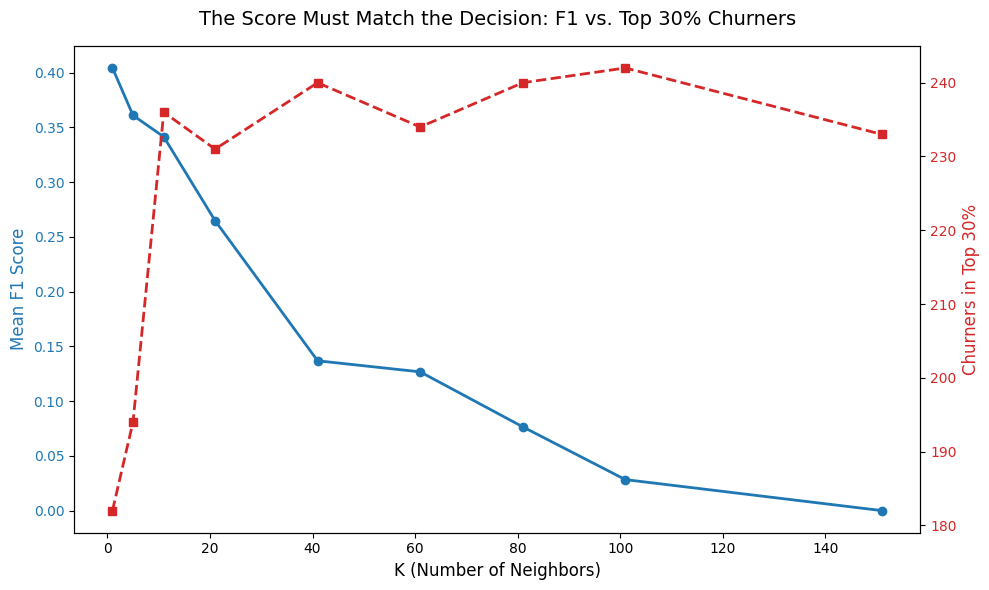

In [8]:
k_values = [1, 5, 11, 21, 41, 61, 81, 101, 151]
results = []

for k in k_values:
    # Set up pipeline with current K
    temp_pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=k))
    ])

    # 1. Cross-validated F1 score (scoring='f1')
    f1_scores = cross_val_score(temp_pipe, X_train[features], y_train, cv=5, scoring='f1')
    mean_f1 = f1_scores.mean()

    # 2. Out-of-fold probability-based top 30% metric
    oof_probs = cross_val_predict(temp_pipe, X_train[features], y_train, cv=5, method='predict_proba')[:, 1]
    churners_found, _ = churners_in_top(oof_probs, y_train, top_share=0.30)

    results.append({
        'K': k,
        'F1 Score': mean_f1,
        'Churners in Top 30%': churners_found
    })

# Create a DataFrame to display results as a table
df_results = pd.DataFrame(results)
print("=== HYPERPARAMETER K SEARCH RESULTS ===")
print(df_results.to_string(index=False))

# Plotting
fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot F1 Score on primary y-axis
color = 'tab:blue'
ax1.set_xlabel('K (Number of Neighbors)', fontsize=12)
ax1.set_ylabel('Mean F1 Score', color=color, fontsize=12)
ax1.plot(df_results['K'], df_results['F1 Score'], marker='o', color=color, linewidth=2, label='CV F1 Score')
ax1.tick_params(axis='y', labelcolor=color)

# Plot Top 30% Churners on secondary y-axis
ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Churners in Top 30%', color=color, fontsize=12)
ax2.plot(df_results['K'], df_results['Churners in Top 30%'], marker='s', color=color, linewidth=2, linestyle='--', label='Churners in Top 30%')
ax2.tick_params(axis='y', labelcolor=color)

plt.title("The Score Must Match the Decision: F1 vs. Top 30% Churners", fontsize=14, pad=15)
fig.tight_layout()
plt.show()

### 5.2 Which K, and why the scores disagree

Which K does each score pick? Why do they disagree so sharply? Which K do you choose for Maria's list,
and why?

*Your answer:*

F1 picks **K = 1** because it has the highest F1 score, about **0.404**. The top 30% score picks **K = 101**, which reaches **242 churners**, the highest number in the call list.

They disagree because F1 judges the model using a classification cutoff, while Maria’s decision is about ranking customers and calling only the top part of the list. A model can have a low F1 score but still rank the highest-risk customers well.

I would choose **K = 101** for Maria because her goal is to reach as many leavers as possible with a limited number of calls. At K = 101, the top 30% list finds the most leavers.

---

## Part 6: The Test Set, Once

### 6.1 Maria's three staffing levels

Refit your chosen Pipeline on all the training rows, on `features`, and score the test set **once**.
The 400 test policyholders stand in for 400 of a month's 1,000 renewals, so Maria's 150, 300 and 500
calls a month become **60, 120 and 200** calls here. Rank the test policyholders by `predict_proba`
and, for each staffing level, report:

- leavers reached (out of the test set's leavers), recall and precision;
- the vote share of the last policyholder called, and how many test policyholders share it;
- the cost of the list (your 1.2 formula), and of a random list of the same length, which reaches
  N × (the test set's churn rate) leavers on average.

Work in the 400 test policyholders (M is the test set's leavers); say so if you scale to a month.
Add the cost of calling nobody, and count how many test policyholders `predict()` flags.

In [9]:
# 1. Refit the Pipeline on all training rows with selected features using chosen K=101
chosen_k = 101
final_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=chosen_k))
])
final_pipe.fit(X_train[features], y_train)

# Predict probabilities on the test set
test_proba = final_pipe.predict_proba(X_test[features])[:, 1]
total_test_churners = y_test.sum()

# Evaluate at Maria's three test-set staffing levels: 60, 120, and 200 calls
call_scenarios = [60, 120, 200]

print(f"=== TEST SET PERFORMANCE (Total Leavers = {total_test_churners} in 400 rows) ===\n")

for n_calls in call_scenarios:
    # Rank test set rows
    order = np.argsort(-test_proba, kind='stable')
    top_indices = order[:n_calls]

    # Count leavers reached
    leavers_reached = y_test.iloc[top_indices].sum()
    recall = leavers_reached / total_test_churners
    precision = leavers_reached / n_calls

    # Last policyholder called details
    last_vote_share = test_proba[order[n_calls - 1]]
    ties = np.sum(test_proba == last_vote_share)

    # Costs (Under James's planning assumption)
    # Each call costs $200. Each leaver not called costs $2800.
    # Total cost = (Calls made * $200) + (Missed Leavers * $2800)
    missed_leavers = total_test_churners - leavers_reached
    scenario_cost = (n_calls * 200) + (missed_leavers * 2800)

    # Random list cost equivalent
    # Random list reaches: n_calls * test_set_churn_rate leavers
    random_reached = n_calls * (total_test_churners / len(y_test))
    random_missed = total_test_churners - random_reached
    random_cost = (n_calls * 200) + (random_missed * 2800)

    print(f"Staffing Level: {n_calls} calls")
    print(f"  Leavers Reached: {leavers_reached} / {total_test_churners} ({recall:.1%} Recall, {precision:.1%} Precision)")
    print(f"  Last Call Probability (Vote Share): {last_vote_share:.3f} ({ties} total rows share this value)")
    print(f"  Model List Cost: ${scenario_cost:,.0f}")
    print(f"  Random List Cost: ${random_cost:,.0f}")
    print(f"  Savings vs Random: ${random_cost - scenario_cost:,.0f}\n")

# Cost of calling nobody (All 104 leavers missed, 0 calls made)
cost_nobody = (0 * 200) + (total_test_churners * 2800)
print(f"Cost of calling nobody: ${cost_nobody:,.0f}")

# Count how many test policyholders predict() flags at default threshold (> 0.5)
test_predictions = final_pipe.predict(X_test[features])
predict_flags = test_predictions.sum()
print(f"Number of test policyholders flagged by default predict(): {predict_flags}")

=== TEST SET PERFORMANCE (Total Leavers = 104 in 400 rows) ===

Staffing Level: 60 calls
  Leavers Reached: 31 / 104 (29.8% Recall, 51.7% Precision)
  Last Call Probability (Vote Share): 0.366 (11 total rows share this value)
  Model List Cost: $216,400
  Random List Cost: $259,520
  Savings vs Random: $43,120

Staffing Level: 120 calls
  Leavers Reached: 59 / 104 (56.7% Recall, 49.2% Precision)
  Last Call Probability (Vote Share): 0.307 (14 total rows share this value)
  Model List Cost: $150,000
  Random List Cost: $227,840
  Savings vs Random: $77,840

Staffing Level: 200 calls
  Leavers Reached: 82 / 104 (78.8% Recall, 41.0% Precision)
  Last Call Probability (Vote Share): 0.238 (9 total rows share this value)
  Model List Cost: $101,600
  Random List Cost: $185,600
  Savings vs Random: $84,000

Cost of calling nobody: $291,200
Number of test policyholders flagged by default predict(): 5


### 6.2 What Maria and James get

At each staffing level, how many leavers does the list reach, and what does it save against a random
list and against calling nobody? Do the last calls on each list clear your break-even from 1.2, and
what does that tell Maria about the temporary help? What did you do about policyholders tied at the
cutoff?

*Your answer:*

At **60 calls**, the model reaches **31 leavers** and saves **$43,120** compared with a random list.&#x20;

At **120 calls**, it reaches **59 leavers** and saves **$77,840** compared with random.&#x20;

At **200 calls**, it reaches **82 leavers** and saves **$84,000** compared with random.&#x20;

All three options also cost much less than calling nobody, which would cost **$291,200**.

The last-call probabilities are **36.6%**, **30.7%**, and **23.8%**, which are all above the **7.1% break-even rate** from Part 1.2. This means even the 200th call still looks worth making, so the temporary help that allows more calls can be useful.

Some policyholders had the same probability at the cutoff. I kept the stable ranked order and stopped at the exact staffing limit instead of adding every tied customer.


---

## Part 7: KNN or the Benchmark?

### 7.1 Aisha's benchmark

Build the benchmark the Week 5 way: a `Pipeline` of `StandardScaler` and
`LogisticRegression(class_weight='balanced')`, on **all** the columns. Choose between it and your KNN
the way K was chosen: by the leavers in the top 30%, out of fold on the training rows. Then report both
on the test set at 60, 120 and 200 calls, once: the test set reports, it does not choose. Also fit the
benchmark on your KNN's `features`: does dropping the flat columns change it as much as it changed
KNN?

In [10]:
# 1. Set up Logistic Regression Pipelines
log_reg_all = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(class_weight='balanced', random_state=42))
])

log_reg_features = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(class_weight='balanced', random_state=42))
])

# 2. Out-of-fold training predictions to compare with KNN (top 30% call capacity = 480)
lr_all_proba = cross_val_predict(log_reg_all, X_train, y_train, cv=5, method='predict_proba')[:, 1]
lr_feat_proba = cross_val_predict(log_reg_features, X_train[features], y_train, cv=5, method='predict_proba')[:, 1]

lr_all_churners, _ = churners_in_top(lr_all_proba, y_train, top_share=0.30)
lr_feat_churners, _ = churners_in_top(lr_feat_proba, y_train, top_share=0.30)

print("=== OUT-OF-FOLD COMPARISON (TRAINING SET - TOP 30% / 480 CALLS) ===")
print(f"KNN (K=101, Selected Features):    {df_results.loc[df_results['K'] == 101, 'Churners in Top 30%'].values[0]} leavers")
print(f"LogReg (All Columns):             {lr_all_churners} leavers")
print(f"LogReg (Selected Features Only):   {lr_feat_churners} leavers\n")

# 3. Fit benchmark on full training set to score the test set once
log_reg_all.fit(X_train, y_train)
lr_test_proba = log_reg_all.predict_proba(X_test)[:, 1]

print("=== TEST SET BENCHMARK COMPARISON ===")
for n_calls in [60, 120, 200]:
    # KNN results from previous step
    knn_order = np.argsort(-test_proba, kind='stable')[:n_calls]
    knn_reached = y_test.iloc[knn_order].sum()

    # Logistic Regression results
    lr_order = np.argsort(-lr_test_proba, kind='stable')[:n_calls]
    lr_reached = y_test.iloc[lr_order].sum()

    print(f"At {n_calls} calls:")
    print(f"  KNN (K=101, Selected Features): Reached {knn_reached} / {total_test_churners} ({knn_reached/total_test_churners:.1%} Recall)")
    print(f"  Logistic Regression (Benchmark): Reached {lr_reached} / {total_test_churners} ({lr_reached/total_test_churners:.1%} Recall)")

=== OUT-OF-FOLD COMPARISON (TRAINING SET - TOP 30% / 480 CALLS) ===
KNN (K=101, Selected Features):    242 leavers
LogReg (All Columns):             223 leavers
LogReg (Selected Features Only):   228 leavers

=== TEST SET BENCHMARK COMPARISON ===
At 60 calls:
  KNN (K=101, Selected Features): Reached 31 / 104 (29.8% Recall)
  Logistic Regression (Benchmark): Reached 33 / 104 (31.7% Recall)
At 120 calls:
  KNN (K=101, Selected Features): Reached 59 / 104 (56.7% Recall)
  Logistic Regression (Benchmark): Reached 55 / 104 (52.9% Recall)
At 200 calls:
  KNN (K=101, Selected Features): Reached 82 / 104 (78.8% Recall)
  Logistic Regression (Benchmark): Reached 74 / 104 (71.2% Recall)


### 7.2 Recommendation to Aisha

Which model do you recommend, on the comparison that is allowed to choose? Does the test set bear it
out, and is the difference big enough to act on? What does each model give ClearView that the other
does not?

*Your answer:*

I would recommend **KNN** based on the allowed training-set comparison. KNN reached **242 leavers** in the top 30%, while Logistic Regression with all columns reached **223**. The test set mostly supports this choice: Logistic Regression does slightly better at 60 calls, but KNN does better at 120 and 200 calls.

The difference is large enough to consider KNN for Maria’s call list because its main goal is ranking the customers most likely to leave. KNN can also capture more complex patterns in the data, while Logistic Regression is easier to explain and gives a simpler benchmark. I would use KNN for the call ranking and keep Logistic Regression as a comparison model.

---

## Part 8: Understanding Demonstration

**Answer these questions WITHOUT AI assistance.** They test your understanding of the material from
the slides and lecture notes.

**Q1:** Aisha's intern says: *"KNN has no coefficients, so scaling can't matter to it."* Explain
what scaling changes for KNN, using one column from this dataset.

*Your answer:*

Scaling matters for KNN because KNN measures the distance between rows. If one feature has much larger numbers than the others, it can control most of that distance. For example, claim_amount_avg had a standard deviation of about 2,178, while many other features had standard deviations below 10. Without scaling, KNN can give too much weight to claim amount even though Part 2 showed that it did not separate churners very well.

**Q2:** A colleague says: *"K = 1 is perfect on the training rows, and it has the best
cross-validated F1. It is clearly the best K."* Both facts are true. Explain why neither one makes
K = 1 the right K for Maria's list.

*Your answer:*

K = 1 looks perfect on the training data because each row is basically its own nearest neighbor, so this is overfitting and does not show how well the model works on new data. It also had the best cross-validated F1, but F1 is not the main score for Maria's decision. Maria has a fixed number of calls and wants to reach as many actual leavers as possible near the top of the list. K = 1 found only 182 leavers in the top 30%, while K = 101 found 242, so K = 101 matches Maria's goal better.

**Q3:** Maria asks why her call list doesn't just come from `model.predict()`. Explain what
`predict()` does with your K, and why it flagged so few of the 400 test policyholders.

*Your answer:*

predict() gives a hard prediction of 0 or 1 based on whether most of the neighbors vote for churn. With K = 101, more than half of those neighbors generally need to be churners for the customer to be predicted as 1. Since churn is only about 26% of the data, reaching that majority is difficult, so the model only flagged 5 of the 400 test customers. Maria needs a ranked list instead, so using predict_proba() is more useful because it lets her call the highest-risk customers even when their score is below 50%.

---

## Part 9: Critical Analysis

Identify the error in each scenario and explain what should be done instead.

**Error 1:** A colleague chooses K with this loop:
```python
best_k, best_count = None, 0
for k in [1, 5, 11, 21, 41, 61, 81, 101, 151]:
    pipe = Pipeline([('scaler', StandardScaler()),
                     ('knn', KNeighborsClassifier(n_neighbors=k))])
    pipe.fit(X_train, y_train)
    count, _ = churners_in_top(pipe.predict_proba(X_test)[:, 1], y_test)
    if count > best_count:
        best_k, best_count = k, count
print(f"Best K = {best_k}: {best_count} leavers in the top 120 test policyholders")
```

*What is wrong, and what should be done instead?*

*Your answer:*

The problem is that the colleague is using the test set to choose K. This causes test-set leakage because the test set is supposed to be used only after the model choices are finished. If we test many K values on the test set and choose the best one, the test result is no longer an unbiased check of the model.

Instead, K should be chosen using only the training data. I would use 5-fold out-of-fold predictions with cross_val_predict() for every K and count the leavers in the top 30%. After choosing K from those training results, I would fit the final model on all training rows and evaluate the test set once.

**Error 2:** Another colleague remembers Week 5's rule, *choose on the training rows*, and
writes:
```python
for k in [1, 5, 11, 21, 41]:
    pipe = Pipeline([('scaler', StandardScaler()),
                     ('knn', KNeighborsClassifier(n_neighbors=k))])
    pipe.fit(X_train, y_train)
    count, n_calls = churners_in_top(pipe.predict_proba(X_train)[:, 1], y_train)
    print(f"K = {k:3d}: {count} leavers in the top {n_calls}")
```
K = 1 puts all 416 training leavers in the top 480, so they choose K = 1.

*Why does K = 1 look perfect here, and what should be done instead?*

*Your answer:*

K = 1 looks perfect because the model is fitted on X_train and then predicts those same training rows. With one neighbor, a training row is usually its own nearest neighbor, so the model can almost memorize the training data. That is why all 416 training leavers can appear in the top 480.

Instead, each training row should be scored by a model that did not train on that row. Using 5-fold cross_val_predict(..., method='predict_proba') gives out-of-fold probabilities and provides a fairer comparison between K values.

---

## Part 10: Reflection and AI Usage Report

Answer these in **your own words**. AI-generated reflections receive zero credit —
they are easy to spot, because they are fluent and say nothing specific.

> **Why this section exists.** You are required to use AI in this course, and using
> it responsibly is a professional skill in its own right — one that has to be
> practised, not assumed. That skill starts here: stating plainly what you asked,
> what came back, how you checked it, and what you changed when the check failed.
> An engineer who cannot account for where their code came from cannot be trusted
> with it, and neither can an analyst. Recounting your own process is how you learn
> to notice it.

### 10.1 Prompt evolution log

Show how at least one of your prompts evolved. What did you ask first, what was
wrong with what you got back, **how did you detect that it was wrong**, and how did
you fix the prompt?

```
Attempt 1: ...
   Result: ...
   How I checked it: ...
   Problem: ...
Attempt 2: ...
   Result: ...
   How I checked it: ...
```

*Your log here:*

```
Attempt 1: I asked Gemini to write the code for Part 2.2 using the training data, grouping small-cardinality columns by their values and the other columns into quartiles.
   Result: The code mostly worked, but for claim_amount_avg it used a try/except block. When pd.qcut() had duplicate edges, the code fell back to pd.cut().
   How I checked it: I compared the code and output with the assignment instructions. The assignment specifically said to use pd.qcut(..., 4, duplicates='drop') for claim_amount_avg. I also noticed that the output had equal-width ranges such as 0 to about 5,343 instead of quantile groups.
   Problem: The code changed the required method from qcut to cut, so the result did not follow the assignment.

Attempt 2: I changed my prompt to clearly say that claim_amount_avg must still use pd.qcut, with duplicates='drop', and that Gemini should not replace it with pd.cut.
   Result: The new code correctly used pd.qcut(train_df[col], 4, duplicates='drop'). It produced three valid groups for claim_amount_avg because duplicate quartile edges were dropped.
   How I checked it: I checked the code directly and reviewed the group sizes and ranges in the output. The result now followed the instructions and ran without an error.
```

### 10.2 Confidence self-assessment

Rate 1 (lost) to 5 (could teach it), and be honest — this is not graded on the
number, it is graded on whether the reflection that follows is candid.

| Topic | 1-5 | What would move this up one point? |
|---|---:|---|
| KNN scaling | 4 | More practice explaining how scaling changes distance between observations. |
| Feature selection | 4 | More practice deciding which weak or flat features should be removed. |
| Cross-validation | 4 | More practice setting up out-of-fold predictions without looking at examples. |
| Choosing K | 4 | More practice comparing different evaluation scores and knowing which one fits the business goal. |
| Business evaluation | 4 | More practice connecting model results to cost, staffing, and business decisions. |
| Logistic Regression vs. KNN | 3 | More practice explaining the strengths and weaknesses of each model and when to use them. |

### 10.3 AI Usage Report

**Required.** Name every AI tool you used, what you used each one for, and attach
the full conversation export as a separate file. Then account for the work: which
outputs you accepted as-is, which you checked and how, which you corrected, and
which you rejected outright. Include **one thing the AI got wrong that you caught**,
and what you had to know to catch it. "I used Gemini for the code" is not a report.

*Your report here:*

I used Gemini mainly to help write the Python code for Parts 2 through 7. I gave it separate prompts for each section so I could run and check the code one step at a time instead of asking it to complete the whole notebook at once.

I did not accept every AI output automatically. I checked whether the code used only the training data where required, whether cross-validation was out of fold, whether the test set was used only after model selection, and whether the printed results matched the instructions. I also compared the outputs with the business goal, especially the number of leavers reached in the top 30%.

One mistake I caught was in Part 2.2. Gemini originally used pd.qcut() for claim_amount_avg, but when duplicate bin edges caused a problem, its code switched to pd.cut(). I knew this was wrong because the assignment specifically required pd.qcut(..., 4, duplicates='drop'). I changed the prompt to make that requirement clear and reran the code. The corrected version kept qcut and produced the expected groups.

I accepted some outputs with only small formatting changes when the code followed the instructions and the results made sense. I corrected the Part 2.2 code because it did not follow the required method. I also removed unnecessary code that reloaded the dataset or repeated earlier setup when the needed variables already existed. I checked later outputs by comparing them with earlier results, such as confirming that scaling improved the KNN list, removing flat features improved the top-30% result, K was chosen using training cross-validation, and the test set was only used for the final evaluation.

The main thing I learned from using AI on this assignment is that code can run successfully and still be wrong for the assignment. I had to understand the workflow and the reason behind each step to know whether the AI output should be accepted or changed.

---

## Video walkthrough

**3–5 minutes, hard stop at five.** Record it in **your own running notebook**, and show:

1. **the cost of a call and of a missed leaver**, your break-even (1.2), and how you judge a call
   list (1.3);
2. **your K plot** (5.1), the K you chose, and why F1 at the vote would have chosen differently (5.2);
3. **your test-set table** at Maria's three staffing levels, scored **once** (6.1), and what it says
   about the temporary help (6.2);
4. **your recommendation to Aisha** (7.2), in one sentence.

Talk the way you would explain it to a colleague; do not read a script. Graders compare the video with
the plots in your notebook.

---

## Before you submit

- [ ] **Runtime → Restart session and run all** (in Colab), top to bottom, with no errors. Save the file *after* it has
      run, so your outputs are in what you upload.
- [ ] Every *Your answer* prompt is filled in, in **your own words** — Part 8 without AI.
- [ ] Your **AI Usage Report** is complete -- the prompting, the results, the checking, the
      re-prompting, and one thing you rejected -- **plus the full conversation export attached as a
      separate file.** The written account alone does not satisfy it.
- [ ] File named **`LastName_FirstName_Week06.ipynb`**.
- [ ] Video recorded and submitted -- **file upload on the Canvas assignment, or a publicly
      accessible link in the Canvas submission comment**. Not in this notebook. Test the link signed
      out: no video, or a link we cannot open, is **-15 points**.